<a href="https://colab.research.google.com/github/abdul-sgf3/PM-Turi4-Clustering-Abdullah-Assegaf/blob/main/PM_TuRi4_Clustering(K_Means)_Abdullah_Assegaf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1

In [32]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
# df berisi usia, pendapatan, skor_belanja (tanpa label)

df = pd.DataFrame({
    'usia': np.random.randint(18, 61, 30),
    'pendapatan': np.random.randint(2300000, 6400001, 30), # Rentang 2.3jt - 6.4jt dengan ukuran 30 data
    'skor_belanja': np.random.randint(1, 101, 30)
})

# Menampilkan data pelanggan
print("Dataset Pelanggan:")
display(df)

# Melihat informasi dataset
print("Ukuran dataset:", df.shape)

# Melakukan scaling data menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['usia', 'pendapatan', 'skor_belanja']])
print("\nVariabel X_scaled berhasil dibuat dengan rentang pendapatan baru!")

Dataset Pelanggan:


,usia,pendapatan,skor_belanja
0,42,5595242,71
1,18,5402180,75
2,36,4591724,33
3,50,4312895,45
4,20,2420756,67
5,46,3356592,35
6,46,4840834,89
7,60,3904125,80
8,41,4020130,13
9,23,4916575,71


Ukuran dataset: (30, 3)

Variabel X_scaled berhasil dibuat dengan rentang pendapatan baru!


Langkah 2

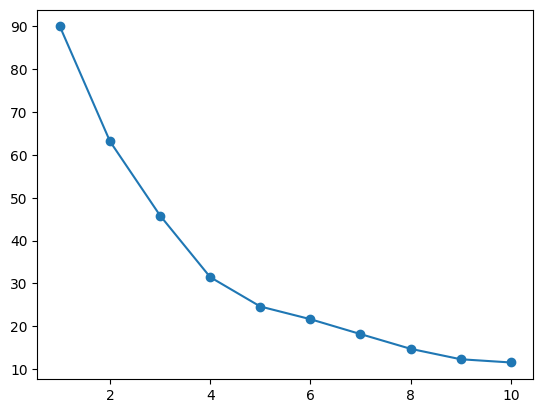

In [33]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()

Langkah 3

In [34]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
0    14
1     8
2     8
Name: count, dtype: int64


Langkah 4

In [35]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.2782738119816562


Langkah 5

In [36]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil

         usia  pendapatan  skor_belanja
cluster                                
0        30.0   4858870.6          55.9
1        51.1   3954118.6          20.8
2        51.4   3910255.9          82.0


# Latihan Mandiri


1. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [37]:
# Run KMeans with K=5
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster_5'] = kmeans_5.fit_predict(X_scaled)

# Calculate silhouette scores
score_3 = silhouette_score(X_scaled, df['cluster'])
score_5 = silhouette_score(X_scaled, df['cluster_5'])

print(f"Silhouette Score for K=3: {score_3:.4f}")
print(f"Silhouette Score for K=5: {score_5:.4f}")

# Comparison
if score_5 > score_3:
    print("\nK=5 has a better silhouette score than K=3.")
else:
    print("\nK=3 has a better silhouette score than K=5.")

Silhouette Score for K=3: 0.2783
Silhouette Score for K=5: 0.3171

K=5 has a better silhouette score than K=3.


2. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [38]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

# Memisahkan fitur asli tanpa scaling
X_unscaled = df[['usia', 'pendapatan', 'skor_belanja']]

# Menjalankan K-Means K=3 tanpa scaling
kmeans_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_unscaled = kmeans_unscaled.fit_predict(X_unscaled)

# Menghitung silhouette score
score_unscaled = silhouette_score(X_unscaled, cluster_unscaled)
score_scaled = silhouette_score(X_scaled, df['cluster'])

print(f"Silhouette Score tanpa scaling (K=3): {score_unscaled:.4f}")
print(f"Silhouette Score dengan scaling (K=3): {score_scaled:.4f}")

Silhouette Score tanpa scaling (K=3): 0.5549
Silhouette Score dengan scaling (K=3): 0.2783



#### **Kesimpulan**
* **Secara matematis**, skor tanpa scaling terlihat lebih bagus (`0.5549`), namun **secara analitis/praktis, hasil ini tidak valid**. Klaster yang terbentuk tidak adil karena bias terhadap fitur ber-angka besar.
* **Scaling wajib dilakukan** agar semua fitur (`usia`, `pendapatan`, dan `skor_belanja`) memiliki bobot kontribusi yang setara dalam menentukan kemiripan antar-pelanggan.

3. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

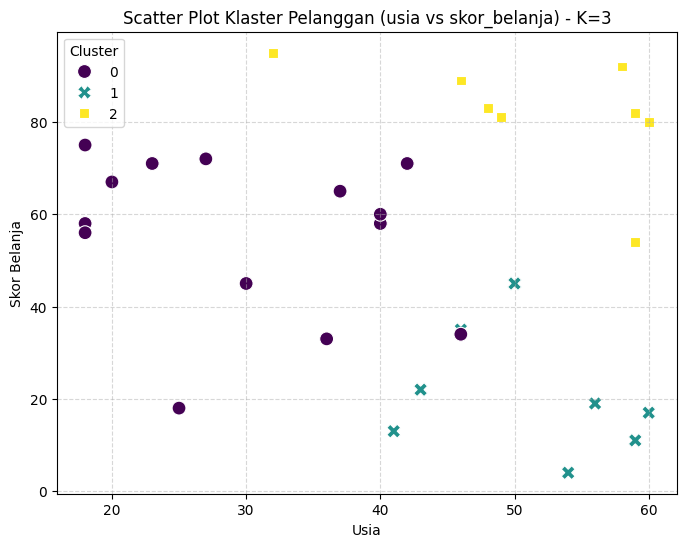

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

# Membuat scatter plot untuk klaster K=3 (dengan scaling)
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='usia',
    y='skor_belanja',
    hue='cluster',
    data=df,
    palette='viridis',
    s=100,
    style='cluster'
)
plt.title('Scatter Plot Klaster Pelanggan (usia vs skor_belanja) - K=3')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Refleksi

1. Bagaimana K-Means menemukan kelompok tanpa label?

    K-Means menemukan kelompok tanpa label dengan cara mengukur jarak (misalnya, Jarak Euclidean) antar data. Algoritma ini memulainya dengan menempatkan sejumlah $K$ titik pusat klaster secara acak (centroid), lalu memasukkan setiap data ke centroid terdekat. Setelah itu, posisi centroid dihitung ulang berdasarkan rata-rata posisi data di klaster tersebut. Proses penyesuaian kelompok dan pembaruan posisi centroid ini dilakukan secara berulang (iteratif) hingga posisi centroid stabil (konvergen).

2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?

    Metode Elbow mengevaluasi nilai inersia (jumlah kuadrat jarak data ke centroid terdekatnya). Ketika $K$ bertambah, nilai inersia pasti akan menurun. Siku (elbow) yang terbentuk di $K=3$ menunjukkan titik transisi di mana penambahan jumlah klaster berikutnya (menjadi $K=4$ atau $K=5$) tidak lagi memberikan penurunan inersia yang signifikan secara drastis. Ini menandakan bahwa membagi data menjadi 3 kelompok sudah cukup optimal untuk menangkap struktur pola variasi data tanpa membuatnya terlalu kompleks.

3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

    Scaling (penskalaan) sangat penting karena algoritma K-Means sangat sensitif terhadap perbedaan skala numerik antar fitur. Dampaknya jika dilewatkan adalah fitur dengan angka nominal yang sangat besar (seperti `pendapatan` dalam jutaan) akan mendominasi perhitungan jarak sepenuhnya, sehingga kontribusi fitur dengan skala kecil (seperti `usia` dan `skor_belanja`) akan diabaikan. Akibatnya, pengelompokan yang terbentuk menjadi bias dan tidak valid secara analitis.